# Прогноз продаж по складам и товарам (команда Монета)

Прогноз недельных продаж на 9 недель (27.07-27.09.2026) для каждой пары склада и товара: 11 складов x 799 товаров x 9 недель = **79 101 строка**. Для обучения можно брать только данные по 26.07.2026.

- Финальная модель (раздел 3): три пары моделей, CatBoost с сидом 42, CatBoost с сидом 7 и LightGBM. Классификатор на 40 признаках оценивает вероятность продажи на неделе, регрессор на 38 признаках оценивает, сколько продадут, если продажа будет. Продажа ставится, если средняя вероятность выше 0.55 на неделях 1-4 и выше 0.5 на неделях 5-9, количество округляется до целого с наименьшим ожидаемым SMAPE, в остальных неделях 0.
- На бэктесте финальная модель лучше v5 на всех трёх фолдах: **0.8077 / 0.8194 / 0.7832** против 0.8091 / 0.8228 / 0.7877. Score считается относительно наивного прогноза "как на прошлой неделе": 0 значит идеально, 1 значит не лучше наивного.

Ноутбук ничего не обучает: числа берутся из `results/` (таблицы экспериментов с Kaggle и история версий) и `model/config.json`, сами эксперименты лежат в `notebooks/05_experiments/`. Пересчитывается за секунды.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sys.path.insert(0, "../src")
import lgbm
from features import GROUPS
from pipeline import smape_choice

R = Path("../results")
MODEL = json.loads(Path("../model/config.json").read_text())
pd.set_option("display.max_colwidth", None)


def fmt(df, formats):
    # только для показа: числа в нужном формате, пропуски как "-"
    out = df.copy()
    for col, f in formats.items():
        out[col] = out[col].map(lambda x: "-" if pd.isna(x) else f.format(x))
    return out
FOLDS = ["season2025", "season2024", "recent"]
DELTAS = [f"Δ {f}" for f in FOLDS]

# цвета как в 02_eda
SURFACE, OTHER = "#fcfcfb", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
sns.set_theme(style="whitegrid", font_scale=0.8, rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.titlesize": 9, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": OTHER, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": OTHER, "ytick.color": OTHER,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.linewidth": 0.8, "lines.linewidth": 1.4,
})

## 1. Задача и метрика

Итоговый скор хакатона складывается из пяти метрик с весами:

| метрика | вес | что ловит |
|---|---|---|
| SMAPE | 50 % | ошибку на каждой паре-неделе в процентах: факт 0 и прогноз 0 дают 0 %, факт 0 и прогноз 0.01 дают 200 % |
| WAPE | 20 % | сумму ошибок к сумме продаж, тут решают ходовые товары |
| RMSE | 15 % | крупные промахи |
| Bias | 10 % | перекос среднего прогноза по каждому ряду |
| RMSLE | 5 % | относительную ошибку (в логарифмах) |

По ТЗ итоговая нормализация ранговая: по каждой метрике считается место среди всех сабмитов. Локально рангов нет, поэтому наш score считается как min-max к наивному прогнозу (бейзлайн организаторов): каждая метрика делится на ту же метрику наивного прогноза, обрезается сверху единицей, и всё складывается с весами. Метрики посчитаны так же, как в `score.py` из ТЗ (сверяли, расхождение 1e-14).

Половина скора - SMAPE по каждой паре-неделе, а больше половины пар-недель нулевые. Если не угадать, будет ли продажа, SMAPE на этой паре-неделе 200 %, поэтому решение разделено на две ступени.

## 2. Что важно в данных

Из `notebooks/02_eda.ipynb`:

| наблюдение | что из этого следует |
|---|---|
| В продажах есть строки только за дни с продажами | строим полную сетку пара x неделя, пропуски заполняем нулями |
| В сезоне 2025 нулевые 56 % пар-недель, обычная ненулевая неделя - 2 штуки | две ступени (будет ли продажа и сколько), количество целое |
| 5 % пар дают ~45 % объёма | WAPE и RMSE решают ходовые пары |
| Треть продаж приходится на дни с нулевым остатком (клиента предупреждают, что товара нет) | нулевой остаток не значит, что продаж не будет: остатки идут признаком, а не правилом |
| Бизнес меняется: в середине 2024 появился склад `wh_10`, категория 1_4 за год выросла на 135 % (продажи в целом на 68 %), скидка у 1_5 составляет 36 % суммы продаж против 8-11 % у остальных | признаки относительно недавнего уровня (тренды, в том числе категории), вес свежих недель |
| Официальных праздников в окне теста нет, перед 1 сентября пик за 1-2 недели | календарь целевой недели: неделя года, месяц, 1 сентября |

## 3. Финальная модель

Финал - это три пары моделей (классификатор и регрессор) и правило, которое собирает из их ответов прогноз. Таблицы ниже строятся из `model/config.json`, то есть из той модели, что лежит в репозитории и работает в контейнере.

```
история пары по неделю T включительно, окно до 24 недель
  -> признаки пары на неделю T: 40 у классификатора, 38 у регрессора
  -> классификатор: вероятность продажи на неделе T+h   CatBoost (сид 42), CatBoost (сид 7), LightGBM -> среднее p
  -> регрессор: сколько продадут, если продажа будет     те же три модели на log1p -> среднее в логарифмах q
  -> p > 0.55 на неделях 1-4 или p > 0.5 на неделях 5-9: целое с наименьшим ожидаемым SMAPE при q, иначе 0
```

- Строка обучения - пара, неделя отсчёта T и горизонт h от 1 до 9. Горизонт тоже признак, поэтому одна модель сразу даёт прогноз на все 9 недель. Признаки считаются только по данным не позже недели T.
- Классификатор учится на всех строках (таргет: была ли продажа), регрессор только на неделях с продажами (таргет: log1p штук).
- Обучение на всей истории по 26.07.2026, недели отсчёта через одну, вес строки 0.5^(возраст недели отсчёта / 26 недель): данные дрейфуют, и свежие недели важнее.
- Окно признаков не длиннее 24 недель, поэтому прогноз по последним 180 дням (столько приходит в контейнер) совпадает с прогнозом по всей истории. Это проверено во всех строках сабмита.

In [2]:
clf_p, reg_p = MODEL["classifier"]["params"], MODEL["regressor"]["params"]
clf_f, reg_f = MODEL["members"][0]["clf_features"], MODEL["members"][0]["reg_features"]
assert all(m["clf_features"] == clf_f and m["reg_features"] == reg_f for m in MODEL["members"])
assert [m["settings"] for m in MODEL["members"]] == [{}, {"random_seed": 7}, {"library": "lightgbm"}]
assert MODEL["decision"]["integer"] == "smape"
near, far = MODEL["decision"]["threshold"]
cat = lambda p: f"{p['loss_function']}, глубина {p['depth']}, lr {p['learning_rate']}, {p['iterations']} деревьев"
lgb = lambda objective: (f"{objective}, {lgbm.PARAMS['num_leaves']} листа, lr {lgbm.PARAMS['learning_rate']}, "
                         f"{lgbm.ROUNDS} деревьев")
display(pd.DataFrame({
    "классификатор": {
        "что предсказывает": "будет ли на неделе хотя бы одна продажа",
        "на каких строках учится": "все пары, недели отсчёта, горизонты 1-9",
        "признаков": len(clf_f),
        "CatBoost, сиды 42 и 7": cat(clf_p),
        "LightGBM": lgb("binary"),
        "как усредняются три модели": "среднее вероятностей",
        "решение": f"продажа, если p > {near} на неделях 1-4 и p > {far} на неделях 5-9",
    },
    "регрессор": {
        "что предсказывает": "log1p штук за неделю, если продажа будет",
        "на каких строках учится": "только недели с продажами",
        "признаков": len(reg_f),
        "CatBoost, сиды 42 и 7": cat(reg_p),
        "LightGBM": lgb("regression"),
        "как усредняются три модели": "среднее в логарифмах",
        "решение": "целое с наименьшим ожидаемым SMAPE, продажи = 1 + Пуассон(q - 1)",
    },
}))
print(f"обучено на данных по {MODEL['train_cutoff']}; каждая {MODEL['classifier']['origin_step']}-я неделя отсчёта; "
      f"вес строки 0.5^(возраст / {MODEL['classifier']['half_life']} недель); окно признаков до {MODEL['window_weeks']} недель")
print("score на бэктесте:", MODEL["backtest"])

,классификатор,регрессор
что предсказывает,будет ли на неделе хотя бы одна продажа,"log1p штук за неделю, если продажа будет"
на каких строках учится,"все пары, недели отсчёта, горизонты 1-9",только недели с продажами
признаков,40,38
"CatBoost, сиды 42 и 7","Logloss, глубина 6, lr 0.1, 400 деревьев","RMSE, глубина 6, lr 0.1, 400 деревьев"
LightGBM,"binary, 63 листа, lr 0.05, 400 деревьев","regression, 63 листа, lr 0.05, 400 деревьев"
как усредняются три модели,среднее вероятностей,среднее в логарифмах
решение,"продажа, если p > 0.55 на неделях 1-4 и p > 0.5 на неделях 5-9","целое с наименьшим ожидаемым SMAPE, продажи = 1 + Пуассон(q - 1)"


обучено на данных по 2026-07-26; каждая 2-я неделя отсчёта; вес строки 0.5^(возраст / 26 недель); окно признаков до 24 недель
score на бэктесте: {'season2025': 0.8077, 'season2024': 0.8194, 'recent': 0.7832}


### Признаки

У всех трёх участников одинаковые наборы. Классификатору нужна активность пары: частота и давность продаж, остатки. Регрессору нужен уровень продаж: средние, обычное количество, цена. В таблице каждая группа из `features.GROUPS` и признаки, которые из неё берёт каждая модель.

In [3]:
rows, unused = [], []
for group, (cols, text) in GROUPS.items():
    c, r = [x for x in cols if x in clf_f], [x for x in cols if x in reg_f]
    if c or r:
        rows.append({"группа": group, "классификатор": ", ".join(c) or "-", "регрессор": ", ".join(r) or "-", "что значат": text})
    else:
        unused.append(group)
features = pd.DataFrame(rows).set_index("группа")
count = lambda col: sum(len(x.split(", ")) for x in features[col] if x != "-")
assert count("классификатор") == len(clf_f) and count("регрессор") == len(reg_f)
print("не используются:", ", ".join(unused))
features

не используются: категория на складе, всплески, появление продажи, динамика скидки, прошлый год


,классификатор,регрессор,что значат
группа,,,
лаги,"lag1, lag2, lag3, lag4","lag1, lag2, lag3, lag4",продажи пары за 1-4 последние недели
уровень,"mean4, mean8","mean4, mean8, mean13, mean24, med8, max8","средние за 4/8/13/24 недели, медиана и максимум недельных продаж за 8 недель"
частота,"nz4, nz8, nz13, nz24, ewm_nz, days4, days8",nz8,"доля недель с продажами (за 4-24 недели и сглаженная, где свежие недели весят больше) и доля дней с продажами (4/8 недель)"
обычное количество,-,"typ8, typ24, qty_per_day8, max_day8","сколько продают, когда продают: за неделю (8/24 недели), за день продаж, максимум за день"
давность,"since_last, since_first, days_since_sale, hist_weeks",-,"недель с последней и первой продажи, дней с последней продажи, недель истории"
тренды,"trend, art_trend, wh_trend, cat_trend, cat2_trend","trend, art_trend, wh_trend, cat_trend, cat2_trend","4 недели к 24: у пары, у товара на всех складах, у всего склада, у категории 1-го и 2-го уровня"
товар на всех складах,"art_mean4, art_nz4","art_mean4, art_nz4",продажи того же товара по всем складам и доля складов с продажами
остатки,"stock, stock_min7, stock_mean28, stock_le0_28, stock_days28, days_since_stock","stock, stock_mean28","остаток на начало воскресенья недели T, минимум за 7 дней, средний за 28, доля дней с остатком <= 0, дней с записью, дней с последнего положительного остатка"
цена и скидка,discount8,"price8, price_trend, discount8","средняя цена за штуку за 8 недель, она же к 24 неделям, доля скидки"


Группы, которые считаются в `features.py`, но в модели не входят: всплески, динамика скидки, категория на складе и появление продажи на сезонных фолдах не помогли (раздел 6), а признаки прошлого года по 180 дням истории пустые.

## 4. Как проверяли

Факта за тест нет, поэтому берём три даты отсечки в прошлом и прогнозируем 9 недель после каждой:

| фолд | история по | прогноз на | зачем |
|---|---|---|---|
| `season2025` | 27.07.2025 | 28.07-28.09.2025 | главный, тот же сезон, что тест |
| `season2024` | 28.07.2024 | 29.07-29.09.2024 | тот же сезон годом раньше |
| `recent` | 24.05.2026 | 25.05-26.07.2026 | самые свежие данные |

**Правило:** идею берём, только если она не хуже базы на обоих сезонных фолдах, а на `recent` хуже не больше чем на 0.005. База считается в том же запуске, потому что обучение на GPU от запуска к запуску плавает примерно на 0.0006 в обе стороны.

## 5. От наивного прогноза до финала

,тип,season2025,season2024,recent,откуда
версия,,,,,
"наивный: ""как на прошлой неделе"" (бейзлайн организаторов)",ориентир,1.0000,1.0000,1.0000,по определению score
нули везде,ориентир,0.9883,0.9838,0.9829,"results/experiments_log.csv, запуск 129"
среднее за 8 недель,ориентир,0.9080,0.9220,0.8872,запуск 130
медиана за 8 недель,ориентир,0.8707,0.9008,0.8458,запуск 131
"среднее за 8 недель, мелочь -> 0, ×1,15 (первый сабмит)",ориентир,0.8410,0.8715,0.8030,запуск 133
"простое правило ""продавали в половине из 8 недель"" + обычное количество",ориентир,0.8535,-,-,"03_classifier, rules_comparison"
"потолок: оракул знает, как часто пара продаётся в тесте",ориентир,0.7744,-,-,"03_classifier, rules_comparison"
"классификатор + регрессор, порог 0,55 (локально, до EDA)",модель,0.8192,0.8463,0.7997,запуск 123
"v1: + тренд категории (Kaggle: глубина 8, lr 0,05)",модель,0.8208,0.8328,0.7928,"05_experiment, 28.10"


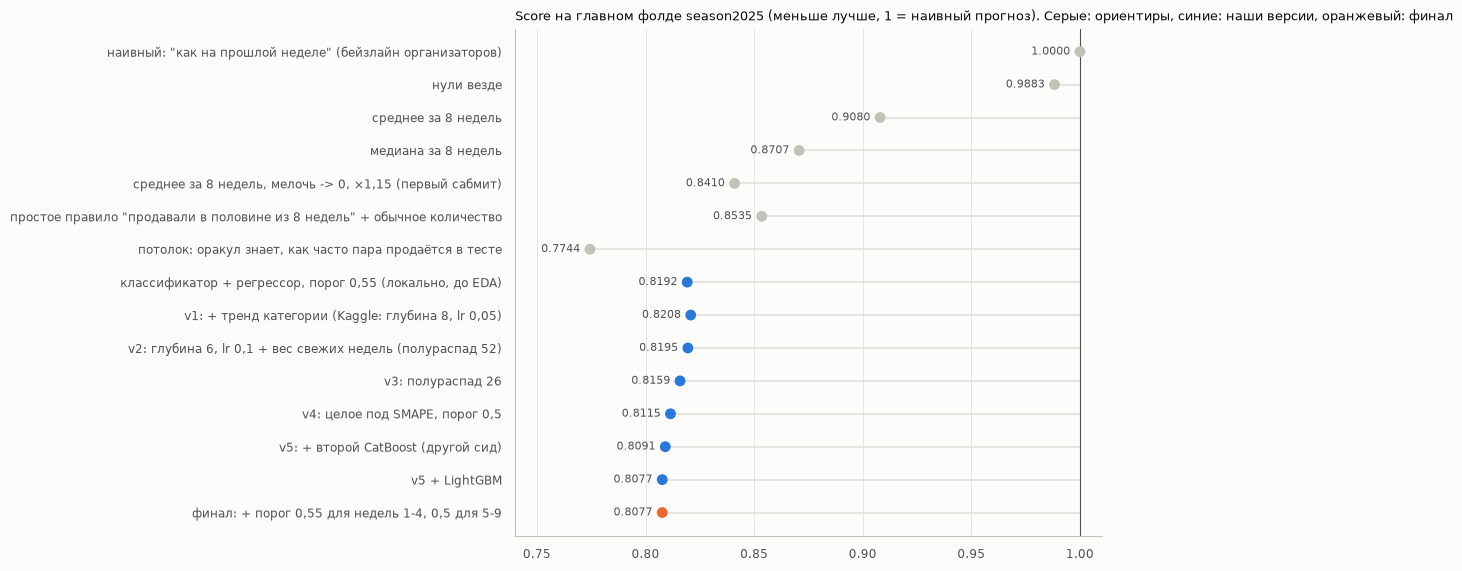

In [4]:
versions = pd.read_csv(R / "versions.csv")
display(fmt(versions, {f: "{:.4f}" for f in FOLDS}).set_index("версия"))

v = versions.dropna(subset=["season2025"])
y = np.arange(len(v))[::-1]
fig, ax = plt.subplots(figsize=(11, 5.6), layout="constrained")
ax.hlines(y, v["season2025"], 1.0, color=GRID, lw=1.2, zorder=1)
ax.scatter(v["season2025"], y, s=46, zorder=3, c=v["тип"].map({"ориентир": OTHER, "модель": BLUE, "финал": ORANGE}))
for yi, s in zip(y, v["season2025"]):
    ax.annotate(f"{s:.4f}", (s, yi), xytext=(-7, 0), textcoords="offset points", ha="right", va="center", fontsize=8, color=INK2)
ax.axvline(1.0, color=INK2, lw=0.8)
ax.set_yticks(y, v["версия"])
ax.set_xlim(0.74, 1.01)
ax.grid(axis="y", visible=False)
ax.set_title("Score на главном фолде season2025 (меньше лучше, 1 = наивный прогноз). Серые: ориентиры, синие: наши версии, оранжевый: финал")
plt.show()

## 6. Что сработало и что нет

Каждая строка - отдельная проверка. Δ - разница score с базой того же запуска (меньше нуля лучше), итог показывает, взяли ли идею в модель.

,группа,итог,Δ season2025,Δ season2024,Δ recent,почему,эксперимент
идея,,,,,,,
"тренд категории (`cat_trend`, `cat2_trend`)",признаки,да,-0.0022,-0.0105,-0.0039,"рост 1_4 общий для всей категории (+135 % к прошлому году), а модель видела тренд только пары, товара и склада","локально, 28.10"
"всплески у регрессора (`spikes16`, `spike_share16`, `bulk24`)",признаки,нет,+0.0009,+0.0051,-0.0022,"всплески локальные и повторяются у тех же пар, но по истории их время не угадать: на сезонных фолдах хуже","локально, 28.10"
динамика скидки (`discount_trend`),признаки,нет,+0.0026,+0.0079,-0.0015,"продажи слабо реагируют на изменение скидки (корреляция Спирмена 0,13-0,15, EDA)","локально, 28.10"
"появление продажи: пополнение остатка, `art_nz1`",признаки,нет,-0.0004,-0.0005,+0.0005,"в пределах шума: признаки остатков (`stock`, `stock_le0_28`, `days_since_stock`) это уже покрывают",05_restock
"категория на складе (`whcat_trend`, `cat_nz4`, ...)",признаки,нет,+0.0071,+0.0001,+0.0015,"на маленьких складах тренд ""склад × категория"" шумный - главный фолд хуже",05_whcat
"глубина 6 и lr 0,1 вместо 8 и 0,05 (+ вес свежести 52)",обучение,да,-0.0013,-0.0012,+0.0009,модель проще - меньше подстраивается под шум редких пар,05_experiment
вес свежих недель: полураспад 26 вместо 52,обучение,да,-0.0036,-0.0018,-0.0013,"данные дрейфуют: новый склад wh_10, рост 1_4, растущие скидки - свежие недели важнее",05_experiment
полураспад 104 вместо 52,обучение,нет,+0.0024,+0.0028,-0.0014,старые недели описывают уже другой бизнес,05_experiment
полураспад 18 вместо 26,обучение,нет,+0.0010,+0.0010,+0.0011,слишком мало истории на редкие пары,05_experiment


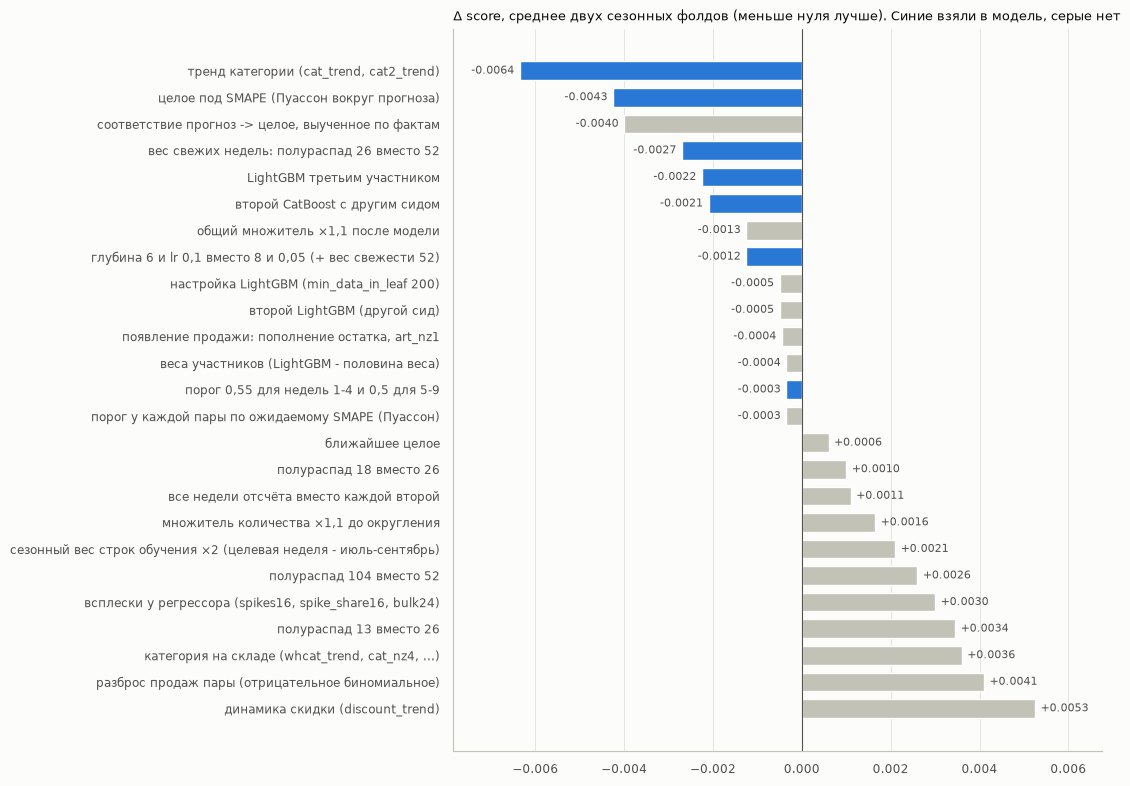

In [5]:
ideas = pd.read_csv(R / "ideas.csv")
display(fmt(ideas[["идея", "группа", "итог", *DELTAS, "почему", "эксперимент"]], {c: "{:+.4f}" for c in DELTAS}).set_index("идея"))

d = ideas.dropna(subset=["Δ season2025"]).assign(m=lambda t: t[["Δ season2025", "Δ season2024"]].mean(axis=1)).sort_values("m")
y = np.arange(len(d))[::-1]
fig, ax = plt.subplots(figsize=(11, 0.27 * len(d) + 1), layout="constrained")
ax.barh(y, d["m"], height=0.7, color=np.where(d["итог"] == "да", BLUE, OTHER))
for yi, m in zip(y, d["m"]):
    ax.annotate(f"{m:+.4f}", (m, yi), xytext=(4 if m > 0 else -4, 0), textcoords="offset points",
                ha="left" if m > 0 else "right", va="center", fontsize=8, color=INK2)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y, d["идея"].str.replace("`", ""))
ax.set_xlim(d["m"].min() - 0.0015, d["m"].max() + 0.0015)
ax.grid(axis="y", visible=False)
ax.set_title("Δ score, среднее двух сезонных фолдов (меньше нуля лучше). Синие взяли в модель, серые нет")
plt.show()

Серые столбики левее нуля - идеи, которые в среднем по сезонам чуть лучше, но в модель не вошли. Самый длинный из них - соответствие прогноз -> целое: на сезонных фолдах оно лучше всех, но на `recent` завышает объём, разбор ниже. Второй LightGBM, веса участников и порог по паре хуже базы на главном фолде `season2025`, правило из раздела 4 они не проходят. Признаки пополнения остатка и настройка LightGBM правило проходят, но выигрыш у них меньше 0.001, это в пределах шума, а каждая такая добавка усложняет модель. Общий множитель после модели проверяли ещё на дробном прогнозе (база v1), а вместе с целым под SMAPE множитель стал хуже на обоих сезонных фолдах (строка "множитель количества ×1,1 до округления"). Порог 0.55 / 0.5 на сезонах тоже выигрывает немного, но его взяли: на `recent` он лучше на 0.0028, а сложности не добавляет. Причина для каждой идеи указана в колонке "почему".

### Сверка с таблицами экспериментов

Для идей, которые проверялись на Kaggle отдельными ноутбуками (`notebooks/05_experiments/`), Δ пересчитывается прямо из сохранённых таблиц `results/experiments/` и совпадает с таблицей выше.

In [6]:
SOURCES = {  # идея: (эксперимент, база, вариант)
    "появление продажи: пополнение остатка, `art_nz1`": ("05_restock", "v5", "классификатор + появление продажи"),
    "категория на складе (`whcat_trend`, `cat_nz4`, ...)": ("05_whcat", "v5 + LightGBM", "+ категория на складе"),
    "сезонный вес строк обучения ×2 (целевая неделя - июль-сентябрь)": ("05_season", "v5", "сезонный вес ×2"),
    "LightGBM третьим участником": ("05_lgbm", "v5", "v5 + LightGBM"),
    "второй LightGBM (другой сид)": ("05_combo", "+ порог 0.55 / 0.5", "+ 2 LightGBM, порог 0.55 / 0.5"),
    "веса участников (LightGBM - половина веса)": ("05_whcat", "v5 + LightGBM", "вес LightGBM 1/2"),
    "настройка LightGBM (`min_data_in_leaf` 200)": ("05_lgbm2", "v5 + LightGBM", "LightGBM min_data_in_leaf 200"),
    "множитель количества ×1,1 до округления": ("05_scale", "v5", "множитель 1.1, порог 0.55"),
    "порог 0,55 для недель 1-4 и 0,5 для 5-9": ("05_scale", "v5", "порог 0.55 / 0.5"),
    "разброс продаж пары (отрицательное биномиальное)": ("05_disp", "v5", "целое по разбросу пары"),
    "соответствие прогноз -> целое, выученное по фактам": ("05_intmap", "лучший конфиг (Пуассон)", "выучено на двух других фолдах"),
}
rows = []
for idea, (exp, base, variant) in SOURCES.items():
    g = pd.read_csv(R / "experiments" / f"grid_{exp}.csv").pivot_table(index="вариант", columns="фолд", values="score")
    delta = (g.loc[variant] - g.loc[base])[FOLDS].round(4)
    table = ideas.set_index("идея").loc[idea, DELTAS].astype(float).round(4)
    rows.append({"идея": idea, "эксперимент": exp, "база": base, "вариант": variant,
                 **dict(zip(DELTAS, delta)), "совпадает": bool(np.allclose(delta.to_numpy(), table.to_numpy()))})
check = pd.DataFrame(rows)
assert check["совпадает"].all()
fmt(check, {c: "{:+.4f}" for c in DELTAS}).set_index("идея")

,эксперимент,база,вариант,Δ season2025,Δ season2024,Δ recent,совпадает
идея,,,,,,,
"появление продажи: пополнение остатка, `art_nz1`",05_restock,v5,классификатор + появление продажи,-0.0004,-0.0005,+0.0005,True
"категория на складе (`whcat_trend`, `cat_nz4`, ...)",05_whcat,v5 + LightGBM,+ категория на складе,+0.0071,+0.0001,+0.0015,True
сезонный вес строк обучения ×2 (целевая неделя - июль-сентябрь),05_season,v5,сезонный вес ×2,+0.0043,-0.0001,-0.0012,True
LightGBM третьим участником,05_lgbm,v5,v5 + LightGBM,-0.0014,-0.0031,-0.0021,True
второй LightGBM (другой сид),05_combo,+ порог 0.55 / 0.5,"+ 2 LightGBM, порог 0.55 / 0.5",+0.0008,-0.0018,-0.0001,True
веса участников (LightGBM - половина веса),05_whcat,v5 + LightGBM,вес LightGBM 1/2,+0.0004,-0.0011,-0.0000,True
настройка LightGBM (`min_data_in_leaf` 200),05_lgbm2,v5 + LightGBM,LightGBM min_data_in_leaf 200,-0.0007,-0.0003,-0.0005,True
"множитель количества ×1,1 до округления",05_scale,v5,"множитель 1.1, порог 0.55",+0.0019,+0.0014,-0.0007,True
"порог 0,55 для недель 1-4 и 0,5 для 5-9",05_scale,v5,порог 0.55 / 0.5,-0.0001,-0.0006,-0.0028,True


### Главный шаг: целое количество, подобранное под метрику

Продают целыми штуками, обычно 1-2 в неделю. Регрессор даёт дробь: на неделях с фактом 1 шт. он в среднем прогнозировал 1.58, это SMAPE 2 * 0.58 / 2.58 = 45 %, а прогноз 1 дал бы 0 %. Лучший точечный прогноз зависит от метрики (для MSE это среднее, для MAE медиана), для SMAPE готовой формулы нет, поэтому целое ищем перебором по ожидаемой ошибке.

- В финале, как и с v4: целое с наименьшим ожидаемым SMAPE, если продажи на неделе с продажей = 1 + Пуассон(q - 1).
- Пробовали соответствие прогноз -> целое, выученное на фактах трёх фолдов (на каждом фолде проверялось соответствие, выученное на двух других). Малые прогнозы оно оставляет 1, а крупные поднимает выше прогноза, потому что регрессор учится на log1p и занижает крупные недели. На сезонных фолдах это лучшая идея (-0.0048 и -0.0032), но на `recent`, самом близком к тесту по времени, соответствие завышает объём (прогноз / факт 0.90 против 0.83 у Пуассона): WAPE, Bias и RMSLE становятся хуже, score тоже (+0.0014). Поэтому в финал его не взяли.
- Общий множитель количества не помог: он поднимает всё подряд, в том числе 1.6 до 2.

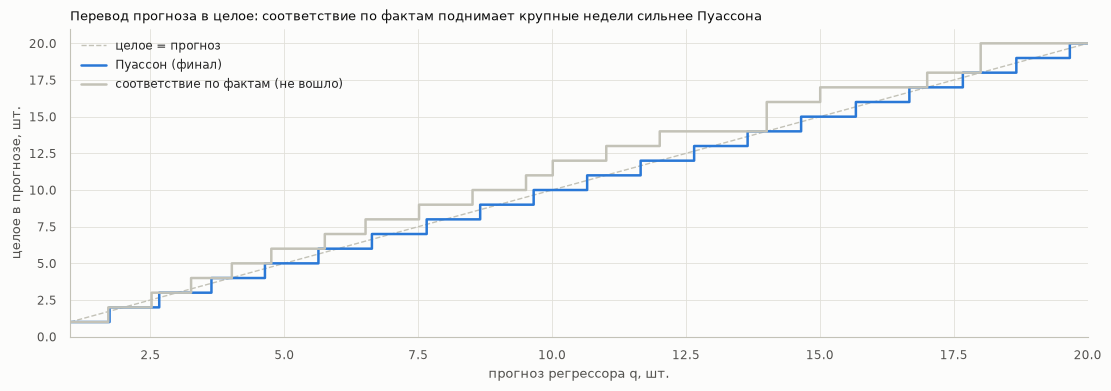

In [7]:
imap = json.loads((R / "integer_map.json").read_text())
edges, ks = np.asarray(imap["edges"]), np.asarray(imap["k"])
q = np.linspace(1, edges[-1] - 1e-6, 800)
learned = ks[np.searchsorted(edges, q, side="right") - 1]
poisson = smape_choice(q[None, :])[0][0]

fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
ax.plot(q, q, color=OTHER, lw=1, ls="--", label="целое = прогноз")
ax.step(q, poisson, where="post", color=BLUE, lw=1.8, label="Пуассон (финал)")
ax.step(q, learned, where="post", color=OTHER, lw=1.8, label="соответствие по фактам (не вошло)")
ax.set(xlabel="прогноз регрессора q, шт.", ylabel="целое в прогнозе, шт.", xlim=(1, 20), ylim=(0, 21))
ax.set_title("Перевод прогноза в целое: соответствие по фактам поднимает крупные недели сильнее Пуассона")
ax.legend(frameon=False, loc="upper left")
plt.show()

## 7. Как воспроизвести

| что | где |
|---|---|
| данные, недели, метрики, бэктест | `src/core.py` |
| признаки | `src/features.py` |
| классификатор, регрессор, LightGBM | `src/classifier.py`, `src/regressor.py`, `src/lgbm.py` |
| ансамбль и решение 0 или k | `src/pipeline.py` |
| итоговый конфиг | `src/final.py` |
| обучение, сохранение в `model/`, прогноз по присланным данным | `src/forecaster.py` |
| анализ данных | `notebooks/02_eda.ipynb` |
| ступени по отдельности | `notebooks/03_classifier.ipynb`, `notebooks/04_regressor.ipynb` |
| все эксперименты | `notebooks/05_experiments/` (таблицы в `results/experiments/`) |
| финальное обучение и сабмит | `notebooks/06_final.ipynb`: `make run NB=06_final` обучает на Kaggle GPU, модели и CSV приходят в `outputs/kaggle/06_final/` |
| модели | `model/` (версия и все настройки в `model/config.json`) |
| сабмит | `submission/submission.csv` |

Что лежит в каждом модуле и файле и почему, описано в `docs/`.